In [1]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = Path("../raw/airbus-ship-detection/train_v2")
CSV_PATH = Path("../raw/airbus-ship-detection/train_ship_segmentations_v2.csv")
CHECKPOINT_PATH = Path(
    "../checkpoints/varuna_segmentation_full_dataset_epoch1.pt"
)

IMAGE_SIZE = 256
THRESHOLD = 0.50

print("Device:", DEVICE)
print("Checkpoint exists:", CHECKPOINT_PATH.exists())
print("Dataset exists:", DATA_DIR.exists())

Device: cuda
Checkpoint exists: True
Dataset exists: True


In [2]:
class ResNet18Segmenter(nn.Module):
    def __init__(self, pretrained_encoder=None):
        super().__init__()

        backbone = resnet18(weights=None)

        if pretrained_encoder is not None:
            backbone.fc = nn.Identity()
            backbone.load_state_dict(pretrained_encoder.state_dict())

        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)

        self.maxpool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        def up_block(in_channels, out_channels):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.up4 = up_block(512 + 256, 256)
        self.up3 = up_block(256 + 128, 128)
        self.up2 = up_block(128 + 64, 64)
        self.up1 = up_block(64 + 64, 64)

        self.output = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        input_size = x.shape[-2:]

        x0 = self.stem(x)
        x1 = self.layer1(self.maxpool(x0))
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)

        d4 = F.interpolate(
            x4, size=x3.shape[-2:], mode="bilinear", align_corners=False
        )
        d4 = self.up4(torch.cat([d4, x3], dim=1))

        d3 = F.interpolate(
            d4, size=x2.shape[-2:], mode="bilinear", align_corners=False
        )
        d3 = self.up3(torch.cat([d3, x2], dim=1))

        d2 = F.interpolate(
            d3, size=x1.shape[-2:], mode="bilinear", align_corners=False
        )
        d2 = self.up2(torch.cat([d2, x1], dim=1))

        d1 = F.interpolate(
            d2, size=x0.shape[-2:], mode="bilinear", align_corners=False
        )
        d1 = self.up1(torch.cat([d1, x0], dim=1))

        logits = self.output(d1)

        return F.interpolate(
            logits, size=input_size, mode="bilinear", align_corners=False
        )


In [3]:
# Load checkpoint into system RAM, not GPU VRAM
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True,
)

# Build the model on CPU
segmenter = ResNet18Segmenter()
segmenter.load_state_dict(checkpoint["model_state_dict"])

# Move model to GPU only after loading
segmenter = segmenter.to(DEVICE)
segmenter.eval()

print("Checkpoint loaded successfully.")
print("Device:", next(segmenter.parameters()).device)
print("Saved threshold:", checkpoint.get("threshold"))
print("Training images:", checkpoint.get("training_images"))

Checkpoint loaded successfully.
Device: cuda:0
Saved threshold: 0.25
Training images: 191756


In [4]:
segmenter.eval()

print("Model ready:", not segmenter.training)
print("Device:", next(segmenter.parameters()).device)
print("Threshold:", THRESHOLD)

Model ready: True
Device: cuda:0
Threshold: 0.5


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(CSV_PATH)

# Keep the same validation split used previously
image_ids = df["ImageId"].drop_duplicates().to_numpy()

_, val_ids = train_test_split(image_ids, test_size=800, random_state=42)

val_df = df[df["ImageId"].isin(val_ids)].copy()

print("Validation images:", len(val_ids))
print("Validation annotation rows:", len(val_df))
print(
    "Images with ships:",
    val_df.groupby("ImageId")["EncodedPixels"]
    .apply(lambda x: x.notna().any())
    .sum(),
)

Validation images: 800
Validation annotation rows: 912
Images with ships: 182


In [ ]:
import numpy as np


def decode_rle(encoded_pixels, height=768, width=768):
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(encoded_pixels):
        return mask.reshape((height, width))

    values = np.asarray(
        encoded_pixels.split(),
        dtype=np.int64,
    )

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    for start, end in zip(starts, ends):
        mask[start:end] = 1

    # Airbus RLE uses column-major order.
    return mask.reshape((width, height)).T

In [ ]:
def calculate_ship_coverage(encoded_pixels):
    mask = decode_rle(encoded_pixels)
    return mask.mean() * 100


coverage_rows = []

for image_id, group in val_df.groupby("ImageId"):
    mask = np.zeros((768, 768), dtype=np.uint8)

    for rle in group["EncodedPixels"].dropna():
        mask |= decode_rle(rle)

    coverage = mask.mean() * 100

    coverage_rows.append(
        {
            "ImageId": image_id,
            "has_ship": int(mask.any()),
            "ship_coverage": coverage,
        }
    )

coverage_df = pd.DataFrame(coverage_rows)

print("Validation images:", len(coverage_df))
print("Images with ships:", coverage_df["has_ship"].sum())
print("Images without ships:", (coverage_df["has_ship"] == 0).sum())

coverage_df.head()

Validation images: 800
Images with ships: 182
Images without ships: 618


,ImageId,has_ship,ship_coverage
0,00189cc36.jpg,0,0.000000
1,00c3b7275.jpg,0,0.000000
2,015da1585.jpg,1,0.005595
3,019545871.jpg,0,0.000000
4,01bd540db.jpg,1,0.030009


In [8]:
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

MASK_SIZE = 768

/home/abhi/Dev/varuna-ssl/.venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
class AirbusSegmentationDataset(Dataset):
    def __init__(self, image_ids, annotations, image_dir, size=256):
        self.image_ids = list(image_ids)
        self.image_dir = Path(image_dir)
        self.size = size

        # Store only non-empty RLE masks, grouped by image.
        self.rle_by_image = (
            annotations.dropna(subset=["EncodedPixels"])
            .groupby("ImageId")["EncodedPixels"]
            .apply(list)
            .to_dict()
        )

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]

        with Image.open(self.image_dir / image_id) as img:
            image = img.convert("RGB")
            image.load()

        mask = np.zeros((MASK_SIZE, MASK_SIZE), dtype=np.uint8)

        for rle in self.rle_by_image.get(image_id, []):
            mask |= decode_rle(rle)

        # Resize image smoothly and mask with nearest-neighbor.
        image = TF.resize(
            image,
            [self.size, self.size],
            interpolation=InterpolationMode.BILINEAR,
        )

        mask = TF.resize(
            Image.fromarray(mask),
            [self.size, self.size],
            interpolation=InterpolationMode.NEAREST,
        )

        image = TF.to_tensor(image)
        image = TF.normalize(
            image,
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        )

        mask = torch.from_numpy(np.array(mask, dtype=np.float32)).unsqueeze(0)

        return image, mask

In [11]:
# Reuse your existing AirbusSegmentationDataset class
val_dataset = AirbusSegmentationDataset(
    image_ids=val_ids, annotations=df, image_dir=DATA_DIR, size=IMAGE_SIZE
)

val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False, num_workers=0, pin_memory=True
)

total_intersection = 0
total_predicted = 0
total_actual = 0
empty_correct = 0
empty_total = 0

In [12]:
with torch.inference_mode():
    for images, masks in tqdm(val_loader, desc="Evaluating"):
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = segmenter(images)
        predictions = (torch.sigmoid(logits) >= THRESHOLD).float()

        total_intersection += (predictions * masks).sum().item()
        total_predicted += predictions.sum().item()
        total_actual += masks.sum().item()

        actual_empty = masks.sum(dim=(1, 2, 3)) == 0
        predicted_empty = predictions.sum(dim=(1, 2, 3)) == 0

        empty_correct += (actual_empty & predicted_empty).sum().item()
        empty_total += actual_empty.sum().item()

dice = (2 * total_intersection) / (total_predicted + total_actual + 1e-8)

iou = total_intersection / (
    total_predicted + total_actual - total_intersection + 1e-8
)

empty_accuracy = empty_correct / max(empty_total, 1)

print(f"Threshold: {THRESHOLD}")
print(f"Pixel-level Dice: {dice:.4f}")
print(f"Pixel-level IoU: {iou:.4f}")
print(f"Empty-image accuracy: {empty_accuracy:.4f}")
print(f"Correctly empty images: {empty_correct}/{empty_total}")

Evaluating: 100%|██████████| 200/200 [00:07<00:00, 25.41it/s]

Threshold: 0.5
Pixel-level Dice: 0.5416
Pixel-level IoU: 0.3713
Empty-image accuracy: 0.9806
Correctly empty images: 606/618


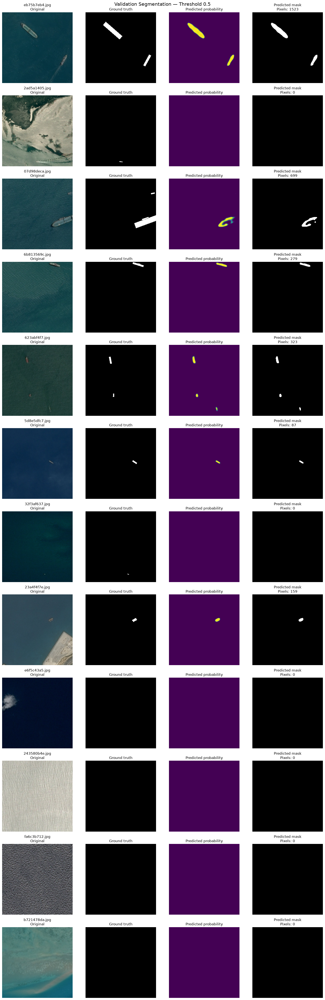

In [ ]:
import random

import matplotlib.pyplot as plt


def show_validation_examples(coverage_df, val_dataset, model, count=8):
    ship_ids = coverage_df.loc[
        coverage_df["has_ship"] == 1, "ImageId"
    ].tolist()

    empty_ids = coverage_df.loc[
        coverage_df["has_ship"] == 0, "ImageId"
    ].tolist()

    random.seed(42)
    selected_ids = random.sample(ship_ids, min(count, len(ship_ids)))
    selected_ids += random.sample(empty_ids, min(4, len(empty_ids)))

    dataset_indices = {
        image_id: i for i, image_id in enumerate(val_dataset.image_ids)
    }

    fig, axes = plt.subplots(
        len(selected_ids), 4, figsize=(16, 4 * len(selected_ids))
    )

    for row, image_id in enumerate(selected_ids):
        idx = dataset_indices[image_id]
        image, mask = val_dataset[idx]

        with torch.inference_mode():
            logits = model(image.unsqueeze(0).to(DEVICE))
            probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

        prediction = probability >= THRESHOLD

        # Undo ImageNet normalization for display.
        original = image.permute(1, 2, 0).numpy()
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        original = np.clip(original * std + mean, 0, 1)

        ground_truth = mask.squeeze().numpy()

        axes[row, 0].imshow(original)
        axes[row, 0].set_title(f"{image_id}\nOriginal")

        axes[row, 1].imshow(ground_truth, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Ground truth")

        axes[row, 2].imshow(probability, cmap="viridis", vmin=0, vmax=1)
        axes[row, 2].set_title("Predicted probability")

        axes[row, 3].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        axes[row, 3].set_title(f"Predicted mask\nPixels: {prediction.sum()}")

        for ax in axes[row]:
            ax.axis("off")

    fig.suptitle(
        f"Validation Segmentation — Threshold {THRESHOLD}", fontsize=16
    )
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()


show_validation_examples(coverage_df, val_dataset, segmenter)

In [ ]:
bins = [-0.001, 0, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, 100]
labels = [
    "No ships",
    "0-0.01%",
    "0.01-0.05%",
    "0.05-0.1%",
    "0.1-0.5%",
    "0.5-1%",
    "1-2%",
    "2-5%",
    ">5%",
]

coverage_df["coverage_group"] = pd.cut(
    coverage_df["ship_coverage"], bins=bins, labels=labels, include_lowest=True
)

print(
    coverage_df.groupby("coverage_group", observed=False)
    .agg(images=("ImageId", "count"), mean_coverage=("ship_coverage", "mean"))
    .round(4)
)

                images  mean_coverage
coverage_group                       
No ships           618         0.0000
0-0.01%              8         0.0051
0.01-0.05%          44         0.0265
0.05-0.1%           16         0.0713
0.1-0.5%            70         0.2826
0.5-1%              20         0.7491
1-2%                13         1.2864
2-5%                10         2.4772
>5%                  1         5.7041


In [16]:
from collections import defaultdict

stats = defaultdict(
    lambda: {
        "n": 0,
        "intersection": 0,
        "pred": 0,
        "actual": 0,
        "detected": 0,
        "missed": 0,
    }
)

coverage_groups = coverage_df.set_index("ImageId")["coverage_group"]

segmenter.eval()

with torch.inference_mode():
    for start in tqdm(range(0, len(val_dataset), 4)):
        batch = [
            val_dataset[i]
            for i in range(start, min(start + 4, len(val_dataset)))
        ]

        images = torch.stack([x[0] for x in batch]).to(DEVICE)
        masks = torch.stack([x[1] for x in batch]).to(DEVICE)

        predictions = (torch.sigmoid(segmenter(images)) >= THRESHOLD).float()

        for j in range(len(batch)):
            image_id = val_dataset.image_ids[start + j]
            group = str(coverage_groups.loc[image_id])

            pred = predictions[j]
            actual = masks[j]

            intersection = (pred * actual).sum().item()
            pred_pixels = pred.sum().item()
            actual_pixels = actual.sum().item()

            s = stats[group]
            s["n"] += 1
            s["intersection"] += intersection
            s["pred"] += pred_pixels
            s["actual"] += actual_pixels

            if actual_pixels > 0:
                if pred_pixels > 0:
                    s["detected"] += 1
                else:
                    s["missed"] += 1

100%|██████████| 200/200 [00:06<00:00, 30.13it/s]


In [17]:
results = []

for group in labels:
    s = stats[str(group)]
    if s["n"] == 0:
        continue

    denominator = s["pred"] + s["actual"]
    union = denominator - s["intersection"]

    results.append(
        {
            "Ship coverage": str(group),
            "Images": s["n"],
            "Dice (%)": round(100 * 2 * s["intersection"] / denominator, 2)
            if denominator
            else 100.0,
            "IoU (%)": round(100 * s["intersection"] / union, 2)
            if union
            else 100.0,
            "Ship detection (%)": round(
                100 * s["detected"] / (s["detected"] + s["missed"]), 2
            )
            if s["detected"] + s["missed"]
            else None,
        }
    )

coverage_results = pd.DataFrame(results)
display(coverage_results)

,Ship coverage,Images,Dice (%),IoU (%),Ship detection (%)
0,No ships,618,0.00,0.00,NaN
1,0-0.01%,8,0.00,0.00,25.00
2,0.01-0.05%,44,3.64,1.85,38.64
3,0.05-0.1%,16,9.32,4.89,56.25
4,0.1-0.5%,70,55.05,37.98,84.29
5,0.5-1%,20,74.90,59.87,100.00
6,1-2%,13,73.66,58.30,92.31
7,2-5%,10,75.59,60.76,90.00
8,>5%,1,13.75,7.38,100.00


In [ ]:
import numpy as np
import torch


def plot_coverage_group(group_name, count=6):
    # Select images belonging to this coverage group
    group_df = coverage_df[
        coverage_df["coverage_group"].astype(str) == group_name
    ]

    if group_df.empty:
        print(f"No images found for group: {group_name}")
        return

    # Sample images from this group
    sample_ids = group_df["ImageId"].tolist()
    random.seed(42)
    sample_ids = random.sample(sample_ids, min(count, len(sample_ids)))

    index_map = {
        image_id: i for i, image_id in enumerate(val_dataset.image_ids)
    }

    fig, axes = plt.subplots(
        len(sample_ids), 4, figsize=(16, 4 * len(sample_ids)), squeeze=False
    )

    segmenter.eval()

    for row, image_id in enumerate(sample_ids):
        image, mask = val_dataset[index_map[image_id]]

        with torch.inference_mode():
            logits = segmenter(image.unsqueeze(0).to(DEVICE))
            probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

        prediction = probability >= THRESHOLD

        # Restore original image colors
        original = image.permute(1, 2, 0).numpy()
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        original = np.clip(original * std + mean, 0, 1)

        actual = mask.squeeze().numpy()

        axes[row, 0].imshow(original)
        axes[row, 0].set_title("Original")

        axes[row, 1].imshow(actual, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Ground Truth")

        axes[row, 2].imshow(probability, cmap="viridis", vmin=0, vmax=1)
        axes[row, 2].set_title("Probability Map")

        axes[row, 3].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        axes[row, 3].set_title("Predicted Mask")

        for ax in axes[row]:
            ax.axis("off")

        axes[row, 0].set_ylabel(image_id, rotation=0, labelpad=65)

    fig.suptitle(
        f"Ship Coverage: {group_name} | Threshold: {THRESHOLD}", fontsize=16
    )
    plt.tight_layout(rect=[0.04, 0, 1, 0.97])
    plt.show()

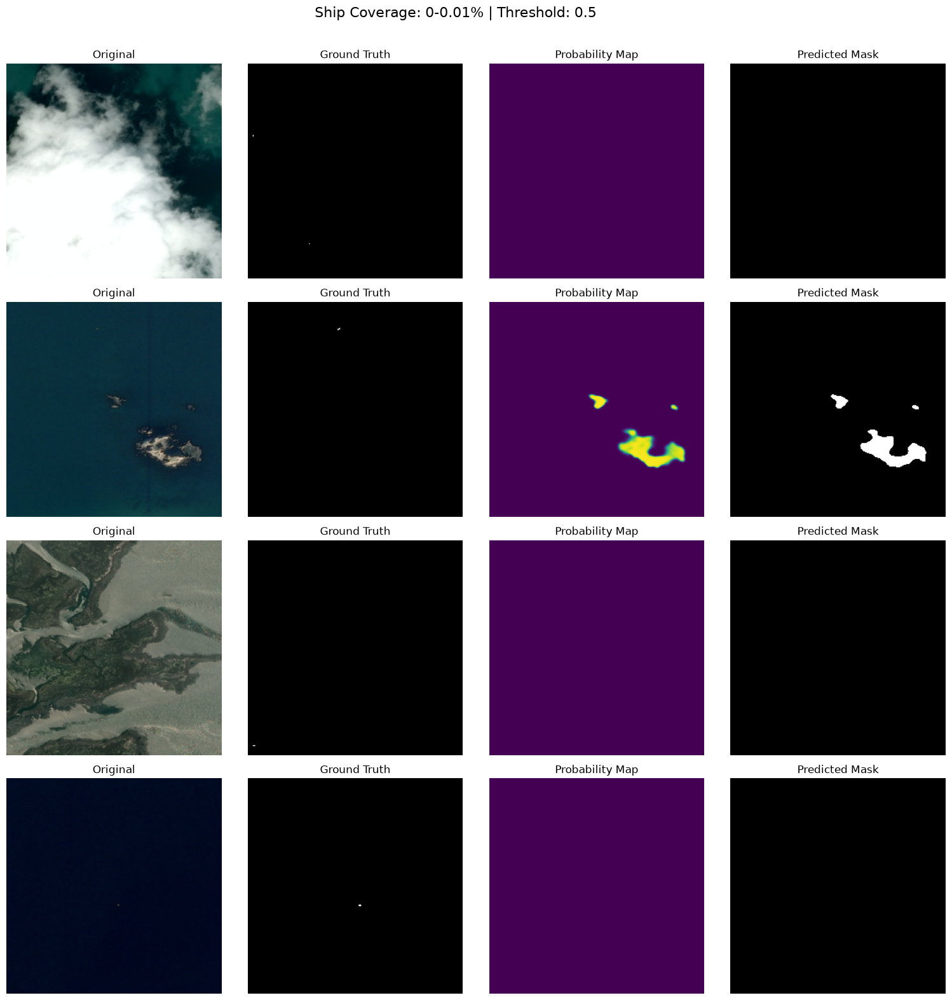

In [27]:
plot_coverage_group("0-0.01%", count=4)


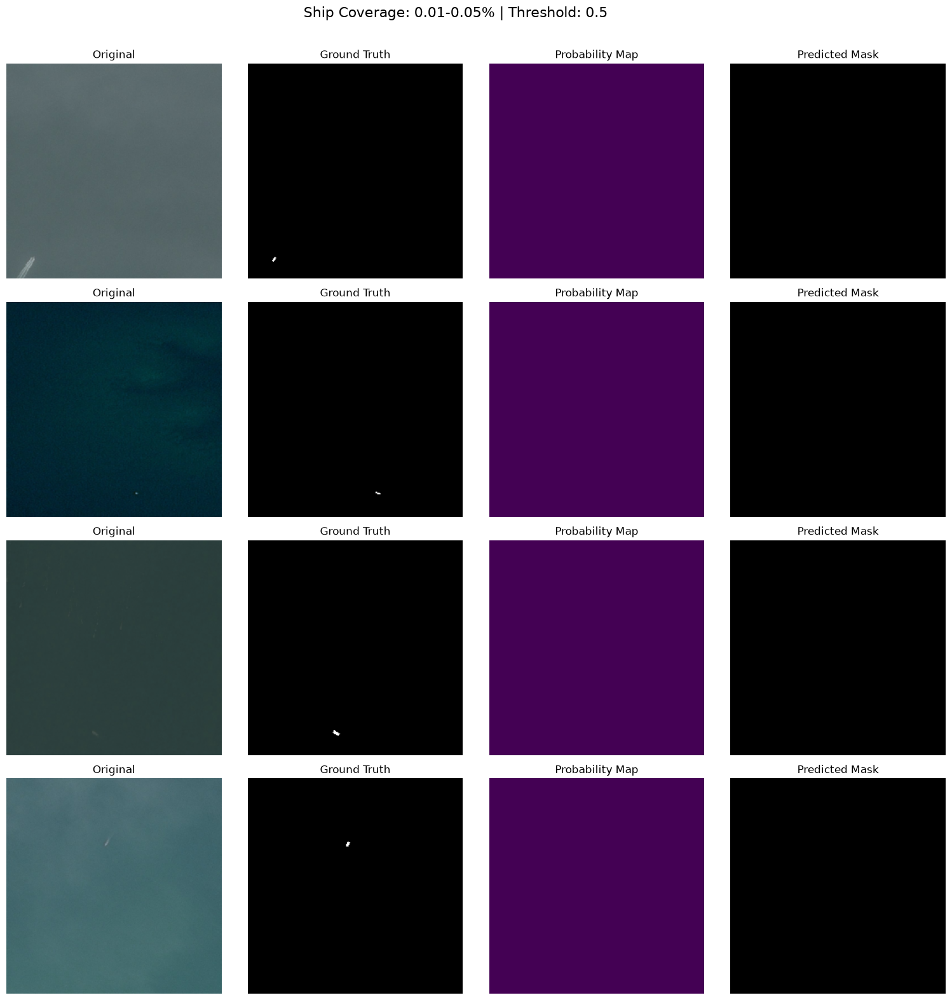

In [28]:
plot_coverage_group("0.01-0.05%", count=4)


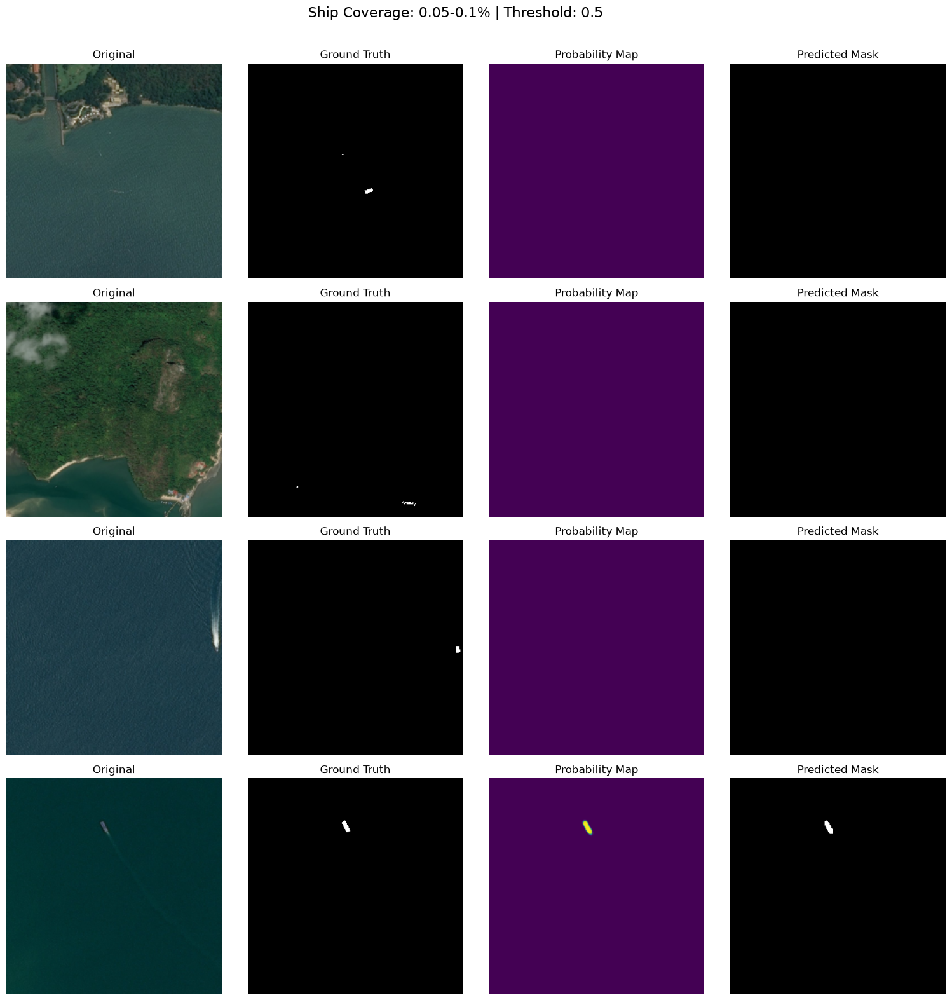

In [33]:
plot_coverage_group("0.05-0.1%", count=4)


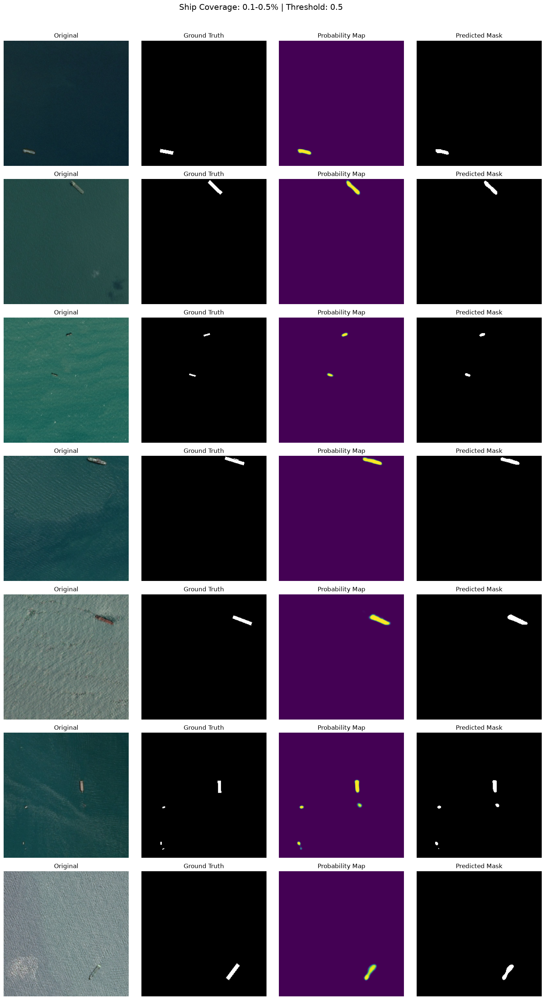

In [34]:
plot_coverage_group("0.1-0.5%", count=7)


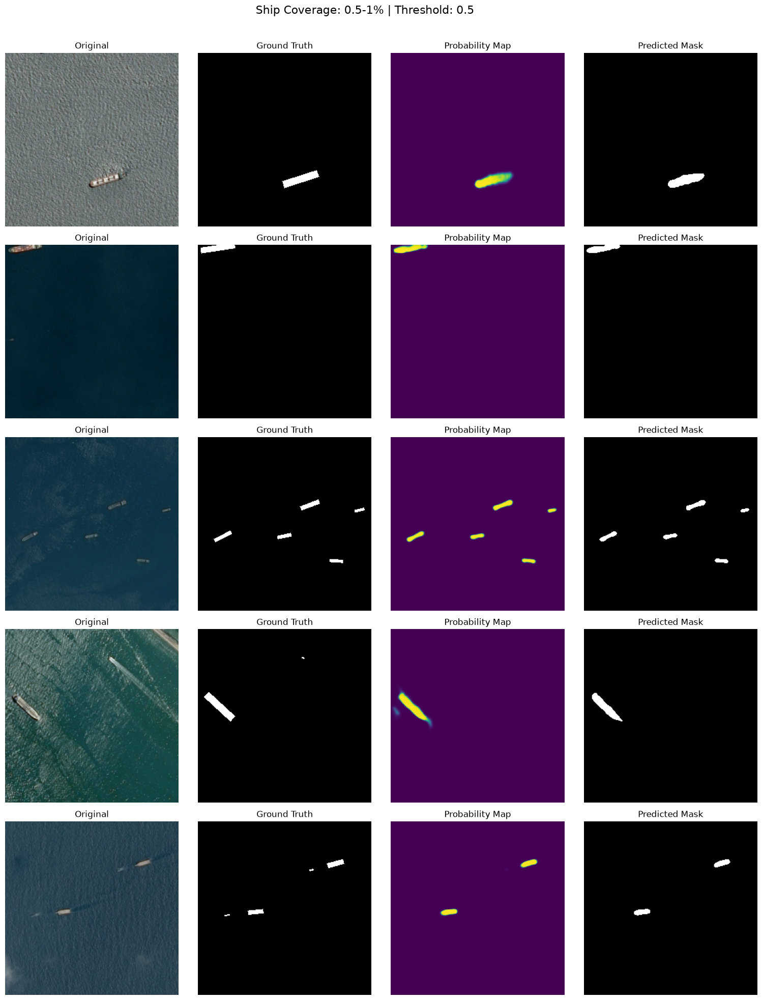

In [40]:
plot_coverage_group("0.5-1%", count=5)


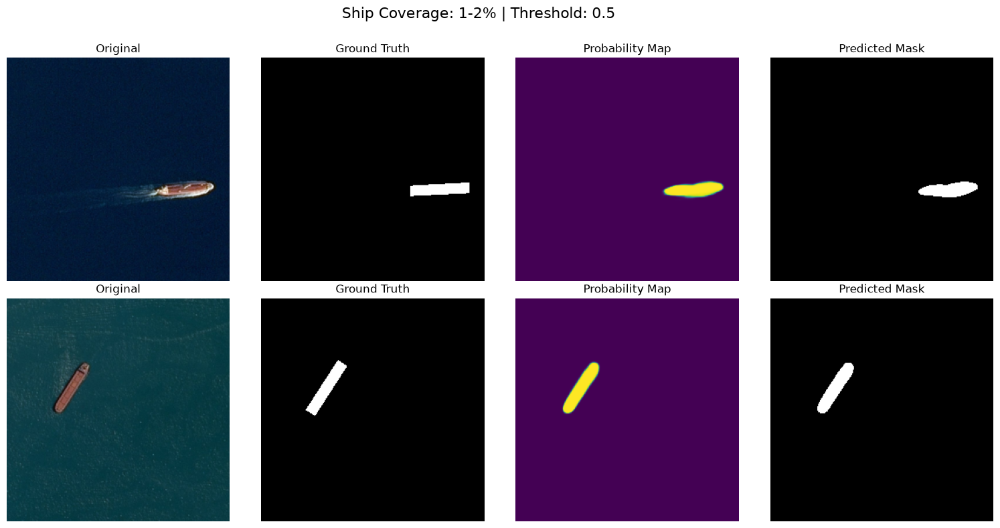

In [42]:
plot_coverage_group("1-2%", count=2)


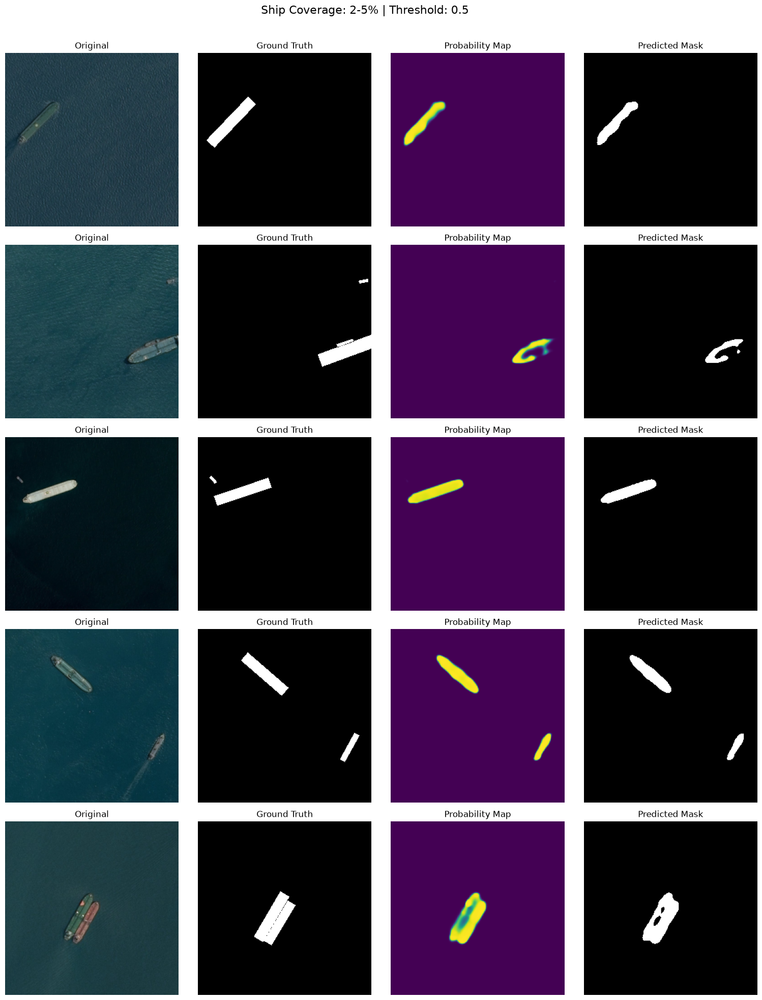

In [45]:
plot_coverage_group("2-5%", count=5)


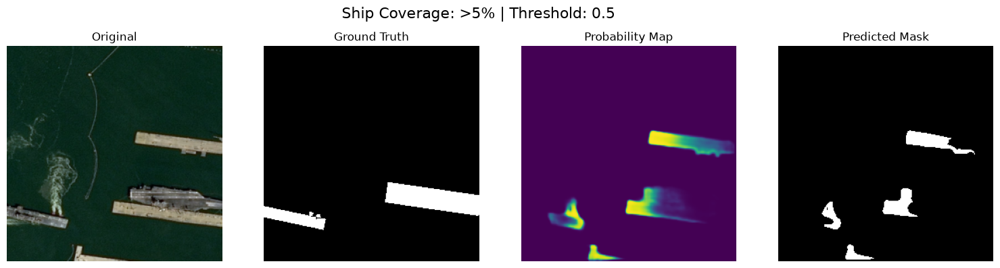

In [46]:
plot_coverage_group(">5%", count=1)


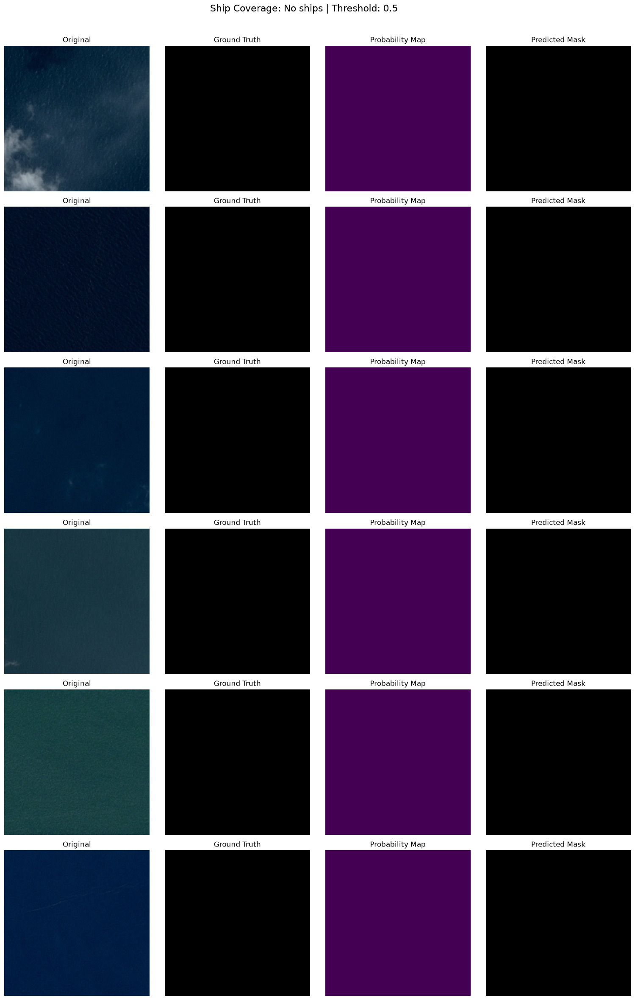

In [47]:
plot_coverage_group("No ships", count=6)